(533, 800)


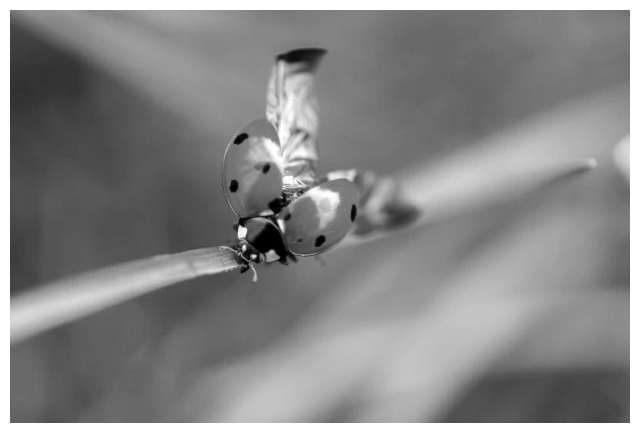

In [8]:
from matplotlib.image import imread
import matplotlib.pyplot as plt
import numpy as np
import os
plt.rcParams['figure.figsize'] = [8,6]

path = r'C:\Users\USER098\Documents\GitHub\matematyka-konkretna\labs\lab1\photo\2.webp'
A = imread(path)

# convert RGB to grayscale
X = np.mean(A,-1) 

print(X.shape)

#img = plt.imshow(256-X)
img = plt.imshow(X)
img.set_cmap('gray')
plt.axis('off')
plt.show()

## Jaka powinna być użyta liczba wartości singularnych żeby zachować 90% informacji na obrazie. 

In [32]:
U, S, VT = np.linalg.svd(X,full_matrices=False)

energy = np.cumsum(S**2) / np.sum(S**2)

r = np.searchsorted(energy, 0.90) + 1

print("Liczba wartości singularnych:", r)
print("Zachowana energia:", energy[r-1] * 100, "%")

Liczba wartości singularnych: 1
Zachowana energia: 93.57144698198964 %


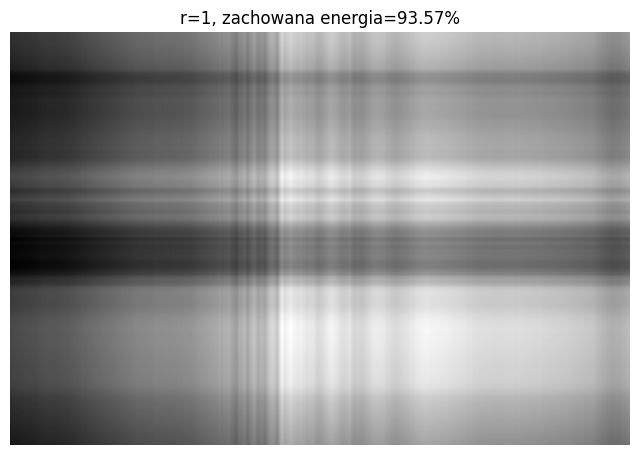

In [35]:
Xapprox = U[:, :r] @ np.diag(S[:r]) @ VT[:r, :]

plt.imshow(Xapprox, cmap='gray')
plt.axis('off')
plt.title(f'r={r}, zachowana energia={energy[r-1]*100:.2f}%')
plt.show()
